# GG4257 - Creating Sustainable Cities with Spatial Data Science
## Lab 4 Challenges
All code cells will include a brief explanation of that code line, in cases where I have used websites or documentation, please refer to the [x] section of the 'references' cell at the end of the notebook to view citations.
### 220016532

### Landon Evans
#### Student ID : _220016532_
#### Github : _land0nevans_
#### URL : https://github.com/land0nevans/UA-Lab2

# Challenge 1 
## Create a Dashboard to map the urban heat effect

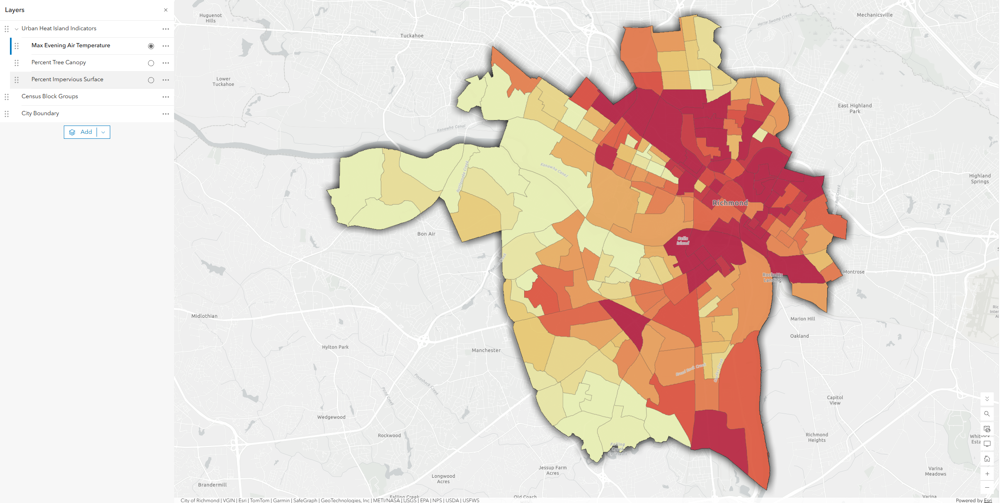


# Challenge 2 
## Choropleth maps

Importing libraries : 

In [22]:
from shapely.geometry import Polygon
import requests
import pandas as pd
import geopandas as gpd
import mapclassify as mc
import matplotlib.pyplot as plt
import folium
import seaborn as sns
import plotly.express as px

## Part 1 (Static Maps)

#### Get the Scottish Index of Multiple Deprivation (SIMD) 2020 dataset and extract the data only for the city of Edinburgh.

In [23]:
# I had difficulty finding a way to filter the shapefile through the website, so I decided to just keep the relevant columns
url = ("https://maps.gov.scot/ATOM/shapefiles/SG_SIMD_2020.zip")

boundaries = gpd.read_file(url)
#boundaries.head()

In [24]:
edinburgh = boundaries[boundaries['LAName'] == 'City of Edinburgh'] # filtering to only show edinburgh
edinburgh.head () # verifying this worked
#edinburgh.explore()

,DataZone,DZName,LAName,SAPE2017,WAPE2017,Rankv2,Quintilev2,Decilev2,Vigintilv2,Percentv2,...,CrimeRate,CrimeRank,HouseNumOC,HouseNumNC,HouseOCrat,HouseNCrat,HouseRank,Shape_Leng,Shape_Area,geometry
1911,S01008417,Balerno and Bonnington Village - 01,City of Edinburgh,708,397,5537,4,8,16,80,...,86,5392.0,17,8,2%,1%,6350.0,20191.721420,1.029993e+07,"POLYGON ((315157.369 666212.846, 315173.727 66..."
1912,S01008418,Balerno and Bonnington Village - 02,City of Edinburgh,691,378,6119,5,9,18,88,...,103,5063.0,7,10,1%,1%,6650.0,25944.861787,2.357050e+07,"POLYGON ((317816.000 666579.000, 318243.000 66..."
1913,S01008419,Balerno and Bonnington Village - 03,City of Edinburgh,541,338,5200,4,8,15,75,...,187,3594.0,30,0,6%,0%,5372.5,5738.935106,1.366457e+06,"POLYGON ((316831.000 667049.000, 316816.000 66..."
1914,S01008420,Balerno and Bonnington Village - 04,City of Edinburgh,466,274,6431,5,10,19,93,...,109,4957.0,2,0,0%,0%,6957.0,1890.096713,1.051967e+05,"POLYGON ((316368.000 666124.000, 316379.297 66..."
1915,S01008421,Balerno and Bonnington Village - 05,City of Edinburgh,884,537,3441,3,5,10,50,...,264,2575.0,61,6,7%,1%,4598.0,2645.609037,1.465441e+05,"POLYGON ((316411.427 666596.771, 316422.940 66..."


In [25]:
edinburgh.set_index('DataZone', inplace=True) # sets datazone code as index 
#edinburgh.head()

#### Create two static choropleth maps (e.g. `matplotlib`). These maps should represent an attribute you find interesting in the SIMD dataset. Using two different classifier methods, you need to show how the maps appear different even though the data and attributes are the same. Include a clear description of your choice and the difference in the classification method for the attribute chosen (e.g. Plotting histograms with breakpoints(bins)).

In [26]:
# edinburgh.crs # mercator projection, need to reproject for plotly
edinburgh = edinburgh.to_crs(4326)
edinburgh.columns

Index(['DZName', 'LAName', 'SAPE2017', 'WAPE2017', 'Rankv2', 'Quintilev2',
       'Decilev2', 'Vigintilv2', 'Percentv2', 'IncRate', 'IncNumDep',
       'IncRankv2', 'EmpRate', 'EmpNumDep', 'EmpRank', 'HlthCIF', 'HlthAlcSR',
       'HlthDrugSR', 'HlthSMR', 'HlthDprsPc', 'HlthLBWTPc', 'HlthEmergS',
       'HlthRank', 'EduAttend', 'EduAttain', 'EduNoQuals', 'EduPartici',
       'EduUniver', 'EduRank', 'GAccPetrol', 'GAccDTGP', 'GAccDTPost',
       'GAccDTPsch', 'GAccDTSsch', 'GAccDTRet', 'GAccPTGP', 'GAccPTPost',
       'GAccPTRet', 'GAccBrdbnd', 'GAccRank', 'CrimeCount', 'CrimeRate',
       'CrimeRank', 'HouseNumOC', 'HouseNumNC', 'HouseOCrat', 'HouseNCrat',
       'HouseRank', 'Shape_Leng', 'Shape_Area', 'geometry'],
      dtype='object')

In [27]:
# reused code from lab, defining classifier variables for natural breaks and equal intervals

# Number of classes for classification
num_classes = 5

# Using Natural Breaks  classification
classifier_nb = mc.NaturalBreaks(edinburgh['HlthDrugSR'], k=num_classes) # sets variables for choropleth + histogram
#print(classifier_nb)
#print(min(classifier_nb.bins), max(classifier_nb.bins))
#print(classifier_nb.bins) 

# Using Equal Interval classification
classifier_ei = mc.EqualInterval(edinburgh['HlthDrugSR'], k=num_classes) # similar to above
#print(classifier_ei)
#print(min(classifier_ei.bins), max(classifier_ei.bins))
#print(classifier_ei.bins)

C:\Users\l4nd0\miniforge3\envs\ua2\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


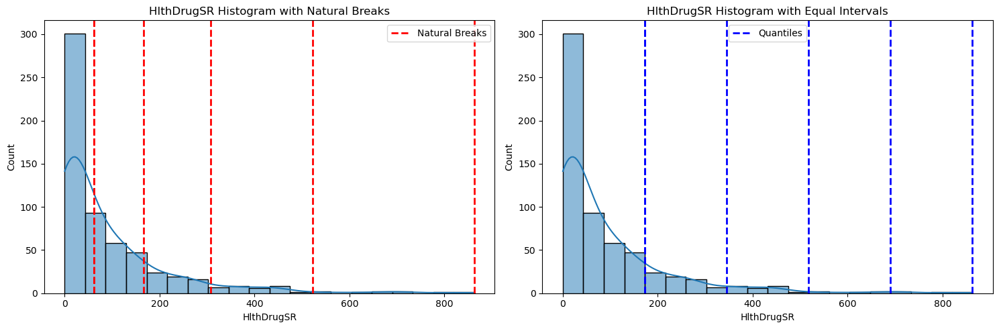

In [28]:
# reuses code from lab, but investigating 'HlthDrugSR' column (Drug-related hospital stays)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=edinburgh, x="HlthDrugSR", ax=axes[0], kde=True, bins=20)
axes[0].axvline(classifier_nb.bins[0], color='red', linestyle='dashed', linewidth=2, label='Natural Breaks')
for bin_value in classifier_nb.bins:
    axes[0].axvline(bin_value, color='red', linestyle='dashed', linewidth=2)
axes[0].set_title("HlthDrugSR Histogram with Natural Breaks")
axes[0].legend()


sns.histplot(data=edinburgh, x="HlthDrugSR", ax=axes[1], kde=True, bins=20)
axes[1].axvline(classifier_ei.bins[0], color='blue', linestyle='dashed', linewidth=2, label='Quantiles')
for bin_value in classifier_ei.bins:
    axes[1].axvline(bin_value, color='blue', linestyle='dashed', linewidth=2)
axes[1].set_title("HlthDrugSR Histogram with Equal Intervals")
axes[1].legend()


plt.tight_layout()
plt.show()

Histograms discussed in cell after figures.

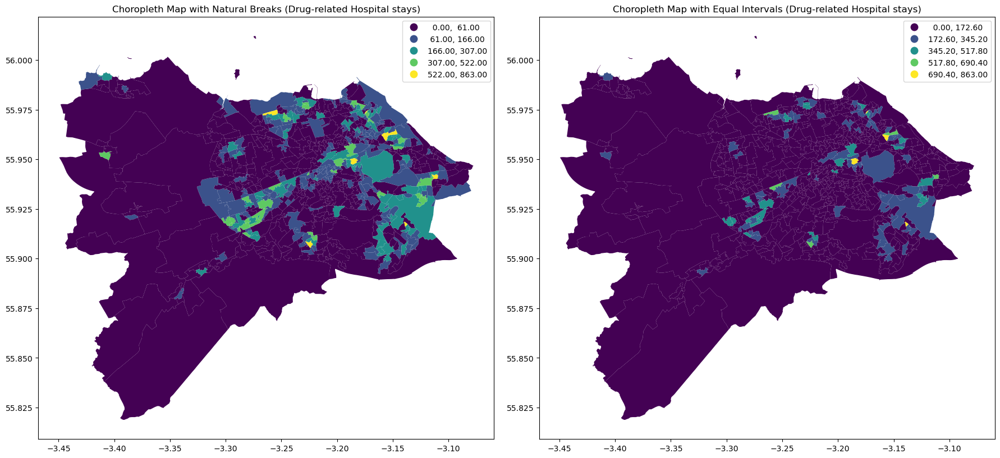

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(18, 8))

edinburgh.plot(column='HlthDrugSR', ax=axs[0], # uses drug related hospital stays variable
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_nb.bins} # sets bins from natural breaks classifier
        )

axs[0].set_title("Choropleth Map with Natural Breaks (Drug-related Hospital stays)") # left side of figure

edinburgh.plot(column='HlthDrugSR', ax=axs[1], 
         legend=True, cmap='viridis',
         scheme='UserDefined',
         classification_kwds={'bins': classifier_ei.bins}) # uses equal intervals classifier

axs[1].set_title("Choropleth Map with Equal Intervals (Drug-related Hospital stays)") # right side of figure

plt.tight_layout() 
plt.show()

I decided to map Edinburgh's drug-related hospital stays for each zone, using 5 classes. I chose Natural Breaks and Equal Intervals as this creates two different visualizations of the same data. Equal intervals splits all the data into 5 classes, regardless of distribution and results in a map that makes most of the city the same colour but only the extreme areas stand out. Natural Breaks, however, selects points in the range that minimises the variance in each class, and on the histogram shows 5 unevenly spaced dotted lines that tend to fall on the 'dips' and follow the shape. When visualized on the map, there are more clear separated areas with low, middle and high HlthDrugSR values and more detailed variation within the city centre compared to the Equal intervals map.

#### Finally, create other two interactive maps (e.g. `choropleth_map`) - one for Glasgow and one for Edinburgh - to represent the difference in deprivation for both cities. Pick any of the available attributes., what is relevant is you can visualise how different both scottish cities are.

## Part 2 (Interactive Maps)

I have copied in the code from the lab for the Glasgow map, which needs to be run to visualize the interactive maps

In [30]:
url_glasgow ="https://maps.gov.scot/server/rest/services/ScotGov/PeopleSociety/MapServer/7/query?where=LAName%3D%27Glasgow+City%27&text=&objectIds=&time=&timeRelation=esriTimeRelationOverlaps&geometry=&geometryType=esriGeometryEnvelope&inSR=&spatialRel=esriSpatialRelIntersects&distance=&units=esriSRUnit_Meter&relationParam=&outFields=*&returnGeometry=true&returnTrueCurves=false&maxAllowableOffset=&geometryPrecision=&outSR=&havingClause=&returnIdsOnly=false&returnCountOnly=false&orderByFields=&groupByFieldsForStatistics=&outStatistics=&returnZ=false&returnM=false&gdbVersion=&historicMoment=&returnDistinctValues=false&resultOffset=&resultRecordCount=&returnExtentOnly=false&sqlFormat=none&datumTransformation=&parameterValues=&rangeValues=&quantizationParameters=&featureEncoding=esriDefault&f=geojson"
# Making the query to the web server, using the Get method from the requests library 
response = requests.get(url_glasgow)
#Now we get the response from the web server, we need to translate that into a format we can manipulate, like JSON.
data = response.json()
gdf = gpd.GeoDataFrame.from_features(data["features"])
gdf = gdf.set_crs('epsg:4326')
#gdf.columns

In [31]:
# creating column to get values from the classifier object
# needed to change 'HlthDrugSR' to 'hlthdrugsr'
num_classes = 5 

classifier_quant = mc.Quantiles(gdf['hlthalcsr'], k=num_classes)
gdf['classification_qn'] = classifier_quant.yb #yb to get the values from the array.


#gdf[['hlthdrugsr', 'classification_qn']]

In [32]:
# repeat for edinburgh
num_classes = 5 

classifier_quant2 = mc.Quantiles(edinburgh['HlthDrugSR'], k=num_classes)
edinburgh['classification_qn'] = classifier_quant2.yb #yb to get the values from the array.


#edinburgh[['HlthDrugSR', 'classification_qn']]

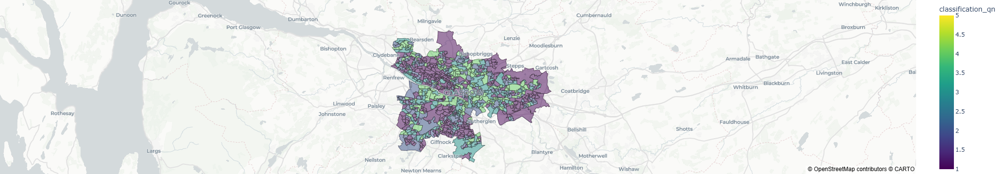

In [33]:
#code provided in lab
fig_glasgow = px.choropleth_map(gdf,
                           geojson=gdf.geometry,
                           locations=gdf.index,
                           color="classification_qn",
                           color_continuous_scale="viridis",
                           range_color= (1, 5),
                           opacity=0.5,
                           center={"lat": 55.866193, "lon": -4.258246},
                           map_style="carto-positron",
                           zoom=9.5)
fig_glasgow.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig_glasgow.show()

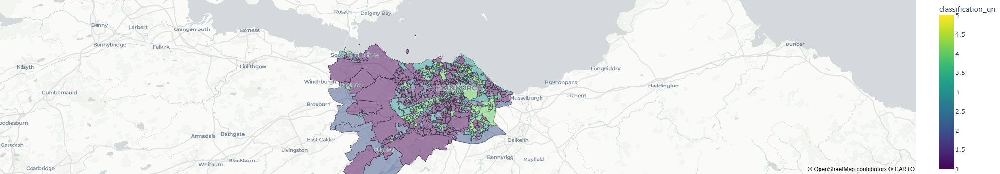

In [34]:
fig_edinburgh = px.choropleth_map(edinburgh,
                           geojson=edinburgh.geometry,
                           locations=edinburgh.index,
                           color="classification_qn",
                           color_continuous_scale="viridis",
                           range_color= (1, 5),
                           opacity=0.5,
                           center={"lat": 55.953251, "lon": -3.188267}, # changed default view position
                           map_style="carto-positron",
                           zoom=9.5)
fig_edinburgh.update_layout(margin={"r":0,"t":0,"l":0,"b":0})
fig_edinburgh.show()

I used Quantiles to classify values as natural breaks is specific to the data and cannot accurately be compared between Glasgow and Edinburgh. In both cities, the higher rates of drug-related hospital stays tend to be small, inner-city zones. Glasgow looks more fragmented and less uniform than Edinburgh's distribution. Edinburgh, generally, has lower rates of drug-related hospital stays in the outer-city areas, while Glasgow is far more mixed and certain neighborhoods or zones in the outer-city still fall within the 4th quantile, moreso in the East and South areas.